<a href="https://colab.research.google.com/github/gleydsonfabricio/handwritten-exam-grader/blob/main/handwritten-exam-grader.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 Corretor Automático de Provas Escritas a Mão

**Projeto de Conclusão — Inteligência Artificial**

Pipeline que recebe a **foto de uma prova manuscrita**, corrige a perspectiva e a qualidade da imagem, extrai o texto com **OCR (TrOCR)**, organiza e limpa as respostas com um **LLM** e, por fim, **corrige automaticamente** cada questão comparando a resposta do aluno com o gabarito fornecido.

## Etapas do pipeline

| Etapa | Descrição |
|---|---|
| 1️⃣ Pré-processamento | Correção de perspectiva ("efeito scanner") e binarização da imagem de baixa qualidade |
| 2️⃣ Carregamento do modelo | TrOCR (`microsoft/trocr-base-handwritten`) para reconhecimento de escrita manuscrita |
| 3️⃣ Segmentação + OCR | Divide a folha em linhas de texto e transcreve cada uma |
| 4️⃣ Limpeza com LLM | Qwen organiza o texto bruto por questão e corrige erros óbvios de OCR |
| 5️⃣ Avaliação automática | Qwen atribui nota e justificativa para cada resposta |



.

## 📦 1. Dependências (instalação + importações)

In [ ]:
!pip install -q transformers tokenizers sentencepiece protobuf
!pip install -q opencv-python-headless numpy
!pip install -q -U google-generativeai
!pip install -q python-dotenv
!pip install -U bitsandbytes>=0.46.1
!pip install python-doctr[torch] -q
!pip install -q sentence-transformers


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.1/69.1 kB 7.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 38.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 89.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 121.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 101.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.9/288.9 kB 30.0 MB/s eta 0:00:00


In [ ]:
import os
import json
import re

import cv2
import torch
import numpy as np
from PIL import Image

from google.colab import files, userdata
from google.colab.patches import cv2_imshow
from google import genai
from google.genai import types
from dotenv import load_dotenv
from huggingface_hub import login

from transformers import (
    TrOCRProcessor,
    VisionEncoderDecoderModel,
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    RobertaTokenizer,
    ViTImageProcessor,
    pipeline,
)
from doctr.models import ocr_predictor
from sentence_transformers import SentenceTransformer, util

## 🖼️ 2. Pré-processamento da imagem (Filtro Básico)

A imagem enviada pode estar torta, mal enquadrada ou em baixa qualidade. Esta etapa:

1. Redimensiona a imagem para acelerar a detecção de contornos;
2. Detecta as bordas da folha (Canny) e encontra o maior contorno de 4 lados;
3. Aplica uma transformação de perspectiva para obter uma visão "de cima" da folha (efeito scanner);
4. Aplica nitidez e binarização adaptativa para destacar o texto manuscrito.

O resultado dessa etapa (`img`) é o que alimenta a extração de texto (OCR) mais abaixo.

In [ ]:
def ordenar_pontos(pts):
    """Ordena os 4 pontos do contorno da folha na ordem:
    [superior-esquerdo, superior-direito, inferior-direito, inferior-esquerdo]
    """
    pts = pts.reshape(4, 2)
    ret = np.zeros((4, 2), dtype="float32")

    s = pts.sum(axis=1)
    ret[0] = pts[np.argmin(s)]
    ret[2] = pts[np.argmax(s)]

    diff = np.diff(pts, axis=1)
    ret[1] = pts[np.argmin(diff)]
    ret[3] = pts[np.argmax(diff)]

    return ret


def processar_imagem_completo(caminho_imagem, mostrar_etapas=True):
    """Corrige a perspectiva da folha na imagem e aplica binarização adaptativa,
    deixando o texto manuscrito pronto para a etapa de OCR.

    Retorna a imagem binarizada (numpy array, escala de cinza) ou None em caso de falha.
    """
    img_original = cv2.imread(caminho_imagem)
    if img_original is None:
        print("Erro ao carregar a imagem.")
        return None

    # Redimensiona para 800px de altura para acelerar a detecção de contornos
    proporcao = 800.0 / img_original.shape[0]
    dimensoes = (int(img_original.shape[1] * proporcao), 800)
    img_redimensionada = cv2.resize(img_original, dimensoes, interpolation=cv2.INTER_AREA)

    if mostrar_etapas:
        print("1️⃣ Imagem redimensionada:")
        cv2_imshow(img_redimensionada)

    img_cinza = cv2.cvtColor(img_redimensionada, cv2.COLOR_BGR2GRAY)
    img_desfoque = cv2.GaussianBlur(img_cinza, (5, 5), 0)
    img_bordas = cv2.Canny(img_desfoque, 75, 200)

    if mostrar_etapas:
        print("2️⃣ Bordas detectadas (Canny):")
        cv2_imshow(img_bordas)

    contornos, _ = cv2.findContours(img_bordas, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    contornos = sorted(contornos, key=cv2.contourArea, reverse=True)

    if len(contornos) == 0:
        print("Não foi possível encontrar nenhum objeto na imagem.")
        return None

    maior_contorno = contornos[0]
    hull = cv2.convexHull(maior_contorno)
    perimetro = cv2.arcLength(hull, True)

    contorno_folha = None
    for multiplicador in [0.02, 0.03, 0.04, 0.05, 0.06]:
        aproximacao = cv2.approxPolyDP(hull, multiplicador * perimetro, True)
        if len(aproximacao) == 4:
            contorno_folha = aproximacao
            break

    if contorno_folha is None:
        print("O contorno detectado não conseguiu formar 4 lados.")
        return None

    if mostrar_etapas:
        img_contorno = img_redimensionada.copy()
        cv2.drawContours(img_contorno, [contorno_folha], -1, (0, 255, 0), 3)
        print("3️⃣ Contorno da folha (4 vértices):")
        cv2_imshow(img_contorno)

    pontos_ordenados = ordenar_pontos(contorno_folha)

    fator_inverso = 1.0 / proporcao
    pontos_originais = (pontos_ordenados * fator_inverso).astype("float32")
    (tl, tr, br, bl) = pontos_originais

    larguraA = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    larguraB = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    largura_maxima = max(int(larguraA), int(larguraB))

    alturaA = np.sqrt(((tr[0] - br[0]) ** 2) + ((tr[1] - br[1]) ** 2))
    alturaB = np.sqrt(((tl[0] - bl[0]) ** 2) + ((tl[1] - bl[1]) ** 2))
    altura_maxima = max(int(alturaA), int(alturaB))

    dst = np.array([
        [0, 0],
        [largura_maxima - 1, 0],
        [largura_maxima - 1, altura_maxima - 1],
        [0, altura_maxima - 1]
    ], dtype="float32")

    # Transformação de perspectiva ("efeito scanner")
    matriz_transformacao = cv2.getPerspectiveTransform(pontos_originais, dst)
    img_escaneada = cv2.warpPerspective(img_original, matriz_transformacao, (largura_maxima, altura_maxima))

    if mostrar_etapas:
        print("4️⃣ Folha após correção de perspectiva:")
        cv2_imshow(img_escaneada)

    # Nitidez (unsharp masking)
    desfoque_suave = cv2.GaussianBlur(img_escaneada, (0, 0), sigmaX=3)
    img_nitida = cv2.addWeighted(img_escaneada, 1.5, desfoque_suave, -0.5, 0)

    # Binarização adaptativa para destacar o texto manuscrito
    img_escaneada_cinza = cv2.cvtColor(img_nitida, cv2.COLOR_BGR2GRAY)
    img_binarizada = cv2.adaptiveThreshold(
        img_escaneada_cinza,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        25,
        15
    )

    if mostrar_etapas:
        print("5️⃣ Folha binarizada (pronta para OCR):")
        cv2_imshow(img_binarizada)

    return img_escaneada, img_binarizada


Saving foto-escrita-a-mao.jpeg to foto-escrita-a-mao.jpeg
1️⃣ Imagem redimensionada:


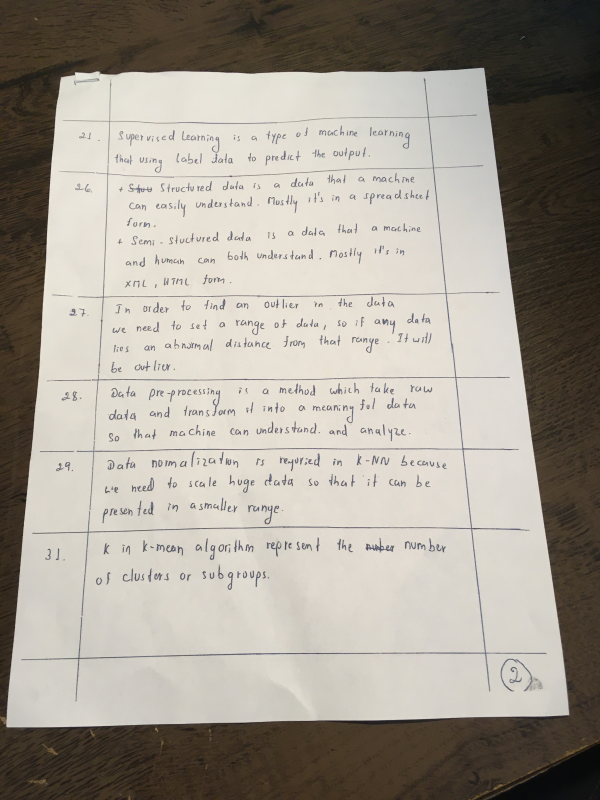

2️⃣ Bordas detectadas (Canny):


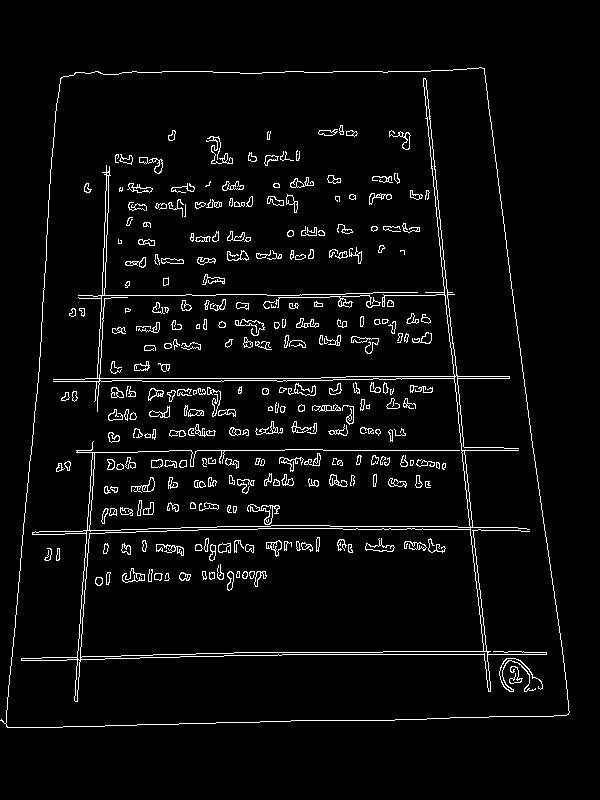

3️⃣ Contorno da folha (4 vértices):


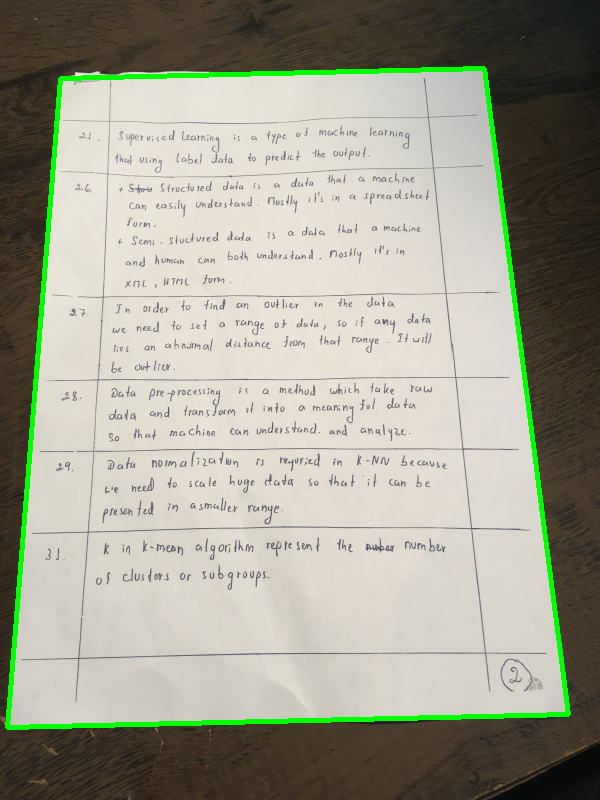

4️⃣ Folha após correção de perspectiva:


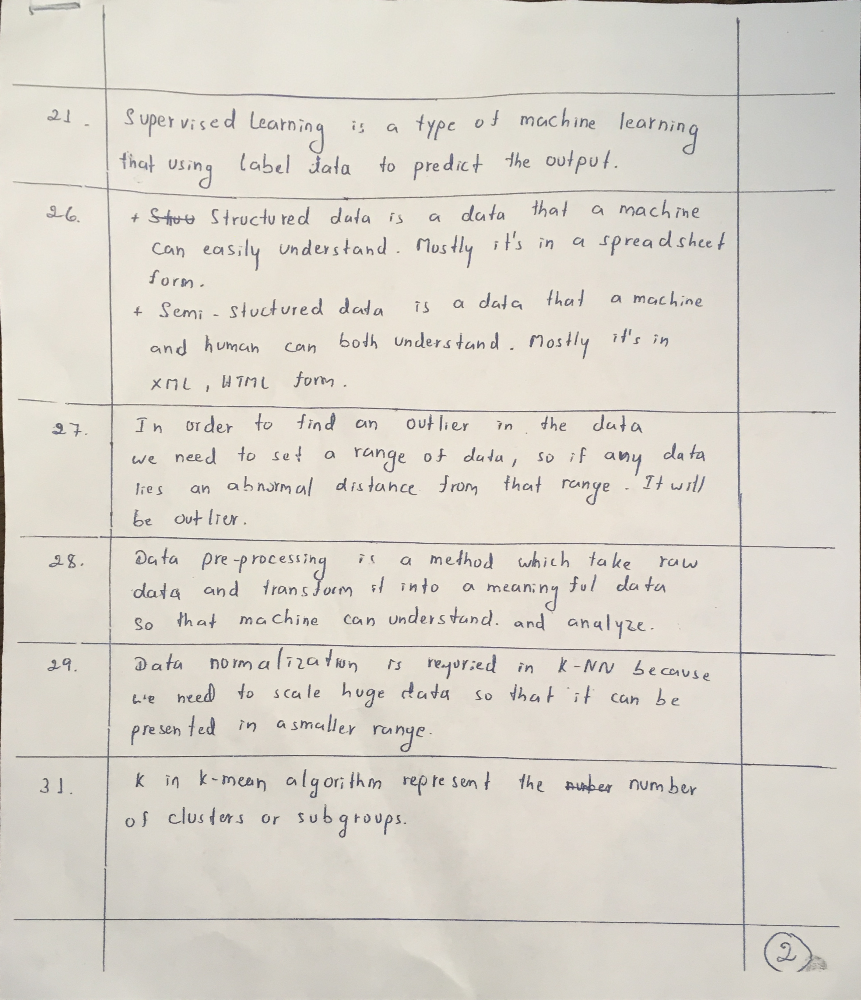

5️⃣ Folha binarizada (pronta para OCR):


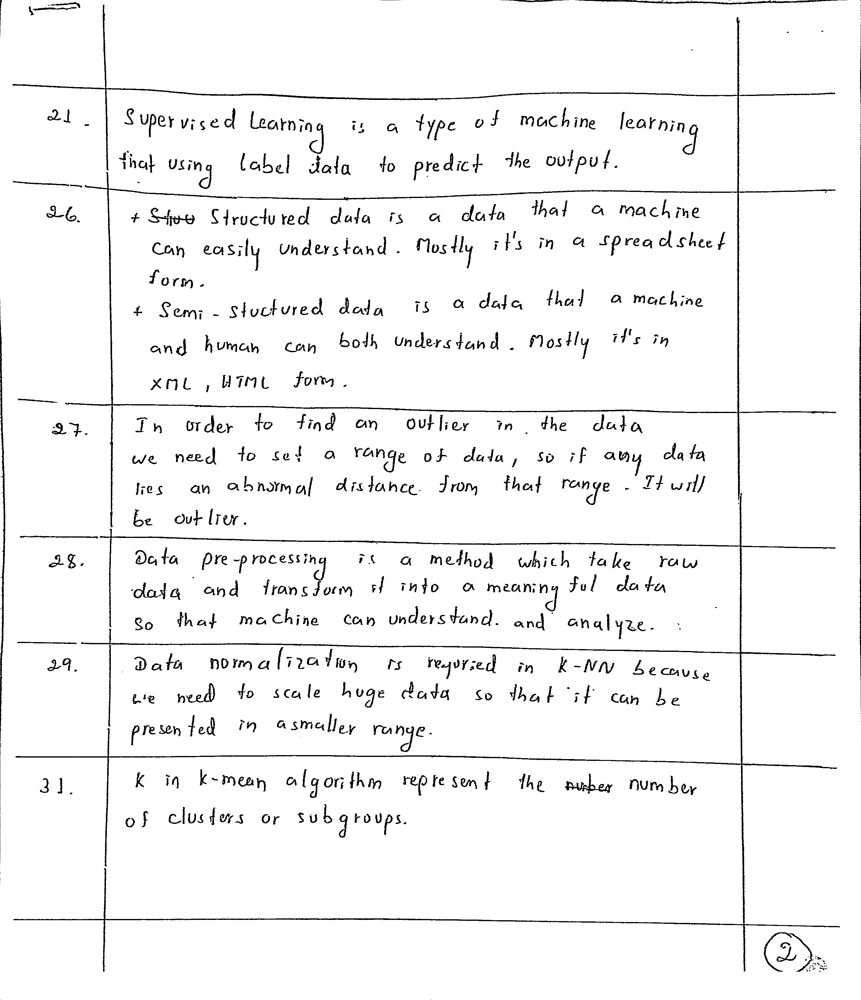

In [ ]:
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

img_rgb_cv, img_bin_cv = processar_imagem_completo(image_path)

if img_rgb_cv is None:
    raise RuntimeError("Não foi possível pré-processar a imagem enviada. Tente novamente com outra foto.")

img_mascara = Image.fromarray(img_bin_cv)
img_para_ocr = Image.fromarray(cv2.cvtColor(img_rgb_cv, cv2.COLOR_BGR2RGB))


## 🔤 3. Carregamento do modelo de OCR (TrOCR)

In [ ]:
token_hf = userdata.get('HF_TOKEN')
login(token=token_hf)

# Carrega tokenizer e image processor separadamente (evita falha na auto-detecção)
tokenizer = RobertaTokenizer.from_pretrained("microsoft/trocr-base-handwritten", force_download=True)
image_processor = ViTImageProcessor.from_pretrained("microsoft/trocr-base-handwritten")
processor = TrOCRProcessor(image_processor=image_processor, tokenizer=tokenizer)

model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten")

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)
model.eval()


tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=False)
          (k_proj): Linear(in_features=768, out_features=768, bias=False)
          (v_proj): Linear(in_features=768, out_features=768, bias=False)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=30

## ✂️ 4. Segmentação de linhas e extração de texto

A imagem da folha é dividida em linhas de texto (removendo linhas estruturais da tabela/caderno) e cada linha é transcrita individualmente pelo TrOCR.

In [ ]:
doctr_predictor = ocr_predictor(
    det_arch="db_resnet50",
    reco_arch="crnn_vgg16_bn",
    pretrained=True
)

def segmentar_linhas_doctr(pil_ocr, margem=5, min_largura_linha=20, min_altura_linha=10):
    """Detecta e recorta linhas de texto manuscrito usando o detector do docTR."""
    img_array = np.array(pil_ocr.convert("RGB"))
    h, w = img_array.shape[:2]

    resultado = doctr_predictor([img_array])

    recortes = []
    coords_recortes = []

    for block in resultado.pages[0].blocks:
        for line in block.lines:
            (x1_rel, y1_rel), (x2_rel, y2_rel) = line.geometry

            x1 = max(0, int(x1_rel * w) - margem)
            y1 = max(0, int(y1_rel * h) - margem)
            x2 = min(w, int(x2_rel * w) + margem)
            y2 = min(h, int(y2_rel * h) + margem)

            largura = x2 - x1
            altura = y2 - y1

            if largura < min_largura_linha or altura < min_altura_linha:
                continue

            crop = pil_ocr.crop((x1, y1, x2, y2))
            recortes.append(crop)
            coords_recortes.append((y1, x1))

    # Ordena os recortes por posição vertical (topo -> base) e depois horizontal
    ordenados = [r for _, r in sorted(zip(coords_recortes, recortes), key=lambda par: (par[0][0], par[0][1]))]

    return ordenados


linhas_img = segmentar_linhas_doctr(img_para_ocr)
print(f"Detectadas {len(linhas_img)} linha(s) de texto reais.")

texto_completo = []
for i, linha_img in enumerate(linhas_img):
    linha_rgb = linha_img.convert("RGB")
    pixel_values = processor(images=linha_rgb, return_tensors="pt").pixel_values
    pixel_values = pixel_values.to(device)

    generated_ids = model.generate(pixel_values, max_new_tokens=100)

    texto_linha = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    texto_completo.append(texto_linha)
    print(f"Linha {i+1}: {texto_linha}")

texto_bruto = "\n".join(texto_completo)

print("\nTexto completo reconhecido:")
print(texto_bruto)


  0%|          | 0/102021912 [00:00<?, ?it/s]

  0%|          | 0/63303144 [00:00<?, ?it/s]

Detectadas 33 linha(s) de texto reais.
Linha 1: supervised learning is a type of machine
Linha 2: learning
Linha 3: 21.
Linha 4: dj
Linha 5: that using label data to predict the output .
Linha 6: id
Linha 7: " Show Structured data is a data that a machine
Linha 8: 26.
Linha 9: can easily understand . Mostly it's in a spreadsheet
Linha 10: form .
Linha 11: a data that a machine
Linha 12: Semi-stuctured data is
Linha 13: of
Linha 14: and human can both understand . Mostly it's in
Linha 15: xril , html form .
Linha 16: In order to find an outlier in the data
Linha 17: 27.
Linha 18: we need to set a range of data , so if any data
Linha 19: res an abnormal distance from that range . ' It will
Linha 20: be outlier .
Linha 21: Data pre-processing is a method which take raw
Linha 22: 28.
Linha 23: data and transborn it into a meaning full data
Linha 24: cj
Linha 25: so that machine can understand . and analyze .
Linha 26: Data normalization is required in K-NN because
Linha 27: 29.
Linha 28: w

## 🧹 5. Limpeza e estruturação do texto com o Qwen

O texto bruto do OCR pode conter erros de reconhecimento e quebras de linha estranhas. Aqui, o Gemini organiza o texto por questão e corrige apenas erros óbvios de OCR.

In [ ]:
model_id = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_id)
model_limpeza = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto"
)

pipe = pipeline("text-generation", model=model_limpeza, tokenizer=tokenizer, return_full_text=False)


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [ ]:
def correct_ocr_text(raw_text, question_context=""):
    system_prompt = """You are an expert AI assistant specialized in post-processing OCR output for student handwritten responses.

            Tasks:
            1. Fix only obvious OCR errors (spelling, misrecognized words, punctuation), without altering the original meaning or rewriting the content.
            2. Identify the number of each question (e.g., "22.", "27.", "30.") and separate the text by question, even if the answer spans multiple lines in the raw text.
            3. If a question has sub-items marked with a dash (e.g., "- Detection:", "- Imputation:"), keep them as sub-items within that question's answer.
            4. If a question's answer is short and in a multiple-choice format (a single letter, or a letter followed by numbers/values, e.g., "C. 2000005", "A.00080000000800000", "1. A"), treat it as an objective question and keep **only the alternative letter**, discarding any numbers that appear alongside it—these numbers are OCR noise, not part of the answer.
            5. Do not invent content that is not in the original text—only correct what is already there.

            Output format (respond ONLY in this format, with no additional comments):
            Question <number>:
            <corrected answer text>

            Question <number>:
            <corrected answer text>
              - <sub-item, if any>
              - <sub-item, if any>"""

    user_prompt = f"""Question Context: {question_context}

                    Raw text:
                    \"\"\"
                    {raw_text}
                    \"\"\"

                    Corrected Text:"""

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]

    prompt_formatted = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    outputs = pipe(
        prompt_formatted,
        max_new_tokens=512,
        temperature=0.0,
        do_sample=False,
        repetition_penalty=1.1
    )

    return outputs[0]["generated_text"].strip()


texto_resposta = correct_ocr_text(texto_bruto)

print("\nTexto limpo:")
print(texto_resposta)


[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'repetition_penalty', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_space


Texto limpo:
Question 21:
supervised learning is a type of machine learning

Question 26:
Show Structured data is a data that a machine can easily understand. Mostly it's in a spreadsheet form.

Question 27:
we need to set a range of data, so if any data res an abnormal distance from that range. ' It will be outlier.

Question 28:
Data pre-processing is a method which take raw data and transform it into a meaningful data so that machine can understand. and analyze.

Question 29:
Data normalization is required in K-NN because we need to scale huge data so that it can be presented in a smaller range.


## ✅ 6. Avaliação automática das respostas

Compara cada resposta do aluno com o gabarito correspondente e atribui uma nota.

In [ ]:
modelo_bert = SentenceTransformer("all-MiniLM-L6-v2")

gabarito_discursivas = {
    21: "A type of ML where the model is trained on labeled data with known inputs and outputs.",
    22: "Overfitting; the model has memorized the training data but failed to generalize.",
    23: "A statistical process for estimating the relationships between a dependent variable and one or more independent variables.",
    24: "Data quality/missing values, overfitting/underfitting, data collection, or time consumption.",
    25: "Healthcare/disease prediction, Finance/fraud detection, E-commerce recommendation systems.",
    26: "Structured is organized in rows/columns (SQL, Excel); Semi-structured has some markers but isn't in a grid (JSON, XML, HTML).",
    27: "Detection: Z-score, IQR, Scatter plots, Box plots. Handling: Trimming, Capping, or Imputation.",
    28: "The steps taken to clean and transform raw data into a format suitable for a machine learning model.",
    29: "K-NN is distance-based; features with larger scales will dominate the distance calculation if not normalized.",
    30: "By grouping values into bins or intervals, e.g., turning ages 1-100 into 'Child,' 'Adult,' 'Senior.'",
    31: "The predefined number of clusters or groups the data will be divided into.",
    32: "K in K-NN, Learning Rate, Number of Estimators/Trees, Max Depth, or Batch Size.",
    33: "An optimization algorithm used to minimize the cost function by iteratively moving toward the steepest descent.",
    34: "Discussion on maximizing the margin and ensuring no data points fall within the 'gutter' or margin.",
    35: "It transforms data into a higher-dimensional space to find a non-linear decision boundary.",
}

# Limiares de similaridade de cosseno -> nota (0.0 a 2.0, passos de 0.5).
# Ajuste esses valores conforme a rigidez de correção desejada.
LIMIARES_NOTA = [
    (0.80, 2.0),
    (0.65, 1.5),
    (0.50, 1.0),
    (0.35, 0.5),
]

def similaridade_para_nota(similaridade):
    for limiar, nota in LIMIARES_NOTA:
        if similaridade >= limiar:
            return nota
    return 0.0

def avaliar_com_bert(resposta_aluno, gabarito):
    """Calcula a similaridade de cosseno entre a resposta do aluno e o gabarito via embeddings do BERT."""
    emb_aluno = modelo_bert.encode(resposta_aluno, convert_to_tensor=True)
    emb_gabarito = modelo_bert.encode(gabarito, convert_to_tensor=True)
    return util.cos_sim(emb_aluno, emb_gabarito).item()


def parse_texto_respostas(texto):
    """Divide o bloco de texto usando Regex com base no padrão 'Question XX:'"""
    padrao = r"Question\s+(\d+):\s*(.*?)(?=(?:Question\s+\d+:|$))"
    matches = re.findall(padrao, texto, re.DOTALL)
    respostas_dict = {}
    for q_num, resp in matches:
        respostas_dict[int(q_num)] = resp.strip()
    return respostas_dict

respostas_aluno = parse_texto_respostas(texto_resposta)

resultados = []
nota_total_discursivas = 0.0

for num_q, resposta_aluno in respostas_aluno.items():
    if num_q not in gabarito_discursivas:
        print(f"⚠️ Questão {num_q} ignorada (não está no gabarito discursivo).")
        continue

    gabarito = gabarito_discursivas[num_q]

    similaridade = avaliar_com_bert(resposta_aluno, gabarito)
    nota = similaridade_para_nota(similaridade)
    justificativa = f"Similaridade semântica com o gabarito: {similaridade:.2f}"

    nota_total_discursivas += nota

    resultados.append({
        "Questao": num_q,
        "Resposta_Aluno": resposta_aluno,
        "Similaridade": round(similaridade, 3),
        "Nota": nota,
        "Justificativa": justificativa
    })

    print(f"  -> Q{num_q} | Similaridade: {similaridade:.2f} | Nota: {nota} | {justificativa}")

print("\n" + "="*50)
print(f"🎉 Avaliação finalizada! Nota Total: {nota_total_discursivas} / {len(resultados) * 2.0}")
print("="*50)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

  -> Q21 | Similaridade: 0.70 | Nota: 1.5 | Similaridade semântica com o gabarito: 0.70
  -> Q26 | Similaridade: 0.65 | Nota: 1.5 | Similaridade semântica com o gabarito: 0.65
  -> Q27 | Similaridade: 0.28 | Nota: 0.0 | Similaridade semântica com o gabarito: 0.28
  -> Q28 | Similaridade: 0.53 | Nota: 1.0 | Similaridade semântica com o gabarito: 0.53
  -> Q29 | Similaridade: 0.71 | Nota: 1.5 | Similaridade semântica com o gabarito: 0.71

🎉 Avaliação finalizada! Nota Total: 5.5 / 10.0
